In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt


PROJECT_ROOT = Path.cwd().parents[1]
DATA_PATH = PROJECT_ROOT / "data" / "H2.csv"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "audit"

PLOT_DIR = PROJECT_ROOT / "outputs" / "eda" / "figures"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (79330, 31)


In [2]:
print("\nDATASET OVERVIEW")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nCOLUMN NAMES")
print(df.columns.tolist())




DATASET OVERVIEW
Number of rows: 79330
Number of columns: 31

COLUMN NAMES
['IsCanceled', 'LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType', 'BookingChanges', 'DepositType', 'Agent', 'Company', 'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'ReservationStatus', 'ReservationStatusDate']


In [3]:
print("\nDATA TYPES")

print(df.dtypes)


DATA TYPES
IsCanceled                       int64
LeadTime                         int64
ArrivalDateYear                  int64
ArrivalDateMonth                   str
ArrivalDateWeekNumber            int64
ArrivalDateDayOfMonth            int64
StaysInWeekendNights             int64
StaysInWeekNights                int64
Adults                           int64
Children                       float64
Babies                           int64
Meal                               str
Country                            str
MarketSegment                      str
DistributionChannel                str
IsRepeatedGuest                  int64
PreviousCancellations            int64
PreviousBookingsNotCanceled      int64
ReservedRoomType                   str
AssignedRoomType                   str
BookingChanges                   int64
DepositType                        str
Agent                              str
Company                            str
DaysInWaitingList                int64
CustomerType 

In [4]:
lost_data = pd.DataFrame({
    "lost_count": df.isna().sum(),
    "lost_percent": df.isna().mean() * 100
})

print("\nMISSING VALUES ==>")
print(lost_data)


MISSING VALUES ==>
                             lost_count  lost_percent
IsCanceled                            0      0.000000
LeadTime                              0      0.000000
ArrivalDateYear                       0      0.000000
ArrivalDateMonth                      0      0.000000
ArrivalDateWeekNumber                 0      0.000000
ArrivalDateDayOfMonth                 0      0.000000
StaysInWeekendNights                  0      0.000000
StaysInWeekNights                     0      0.000000
Adults                                0      0.000000
Children                              4      0.005042
Babies                                0      0.000000
Meal                                  0      0.000000
Country                              24      0.030253
MarketSegment                         0      0.000000
DistributionChannel                   0      0.000000
IsRepeatedGuest                       0      0.000000
PreviousCancellations                 0      0.000000
Previous

In [5]:
duplicate_count = df.duplicated().sum()

print("number of douplicate rows ==>: \n", duplicate_count)

number of douplicate rows ==>: 
 25902


In [6]:
# Summary for numerical columns
numerical_summary = df.describe(include="number")

# Summary for categorical columns
categorical_summary = df.describe(include=["str", "object", "category"])

print("\nNUMERICAL SUMMARY")
print(numerical_summary)

print("\nCATEGORICAL SUMMARY")
print(categorical_summary)


NUMERICAL SUMMARY
         IsCanceled      LeadTime  ArrivalDateYear  ArrivalDateWeekNumber  \
count  79330.000000  79330.000000     79330.000000           79330.000000   
mean       0.417270    109.735724      2016.174285              27.177449   
std        0.493111    110.948526         0.699181              13.398523   
min        0.000000      0.000000      2015.000000               1.000000   
25%        0.000000     23.000000      2016.000000              17.000000   
50%        0.000000     74.000000      2016.000000              27.000000   
75%        1.000000    163.000000      2017.000000              38.000000   
max        1.000000    629.000000      2017.000000              53.000000   

       ArrivalDateDayOfMonth  StaysInWeekendNights  StaysInWeekNights  \
count           79330.000000          79330.000000       79330.000000   
mean               15.786625              0.795185           2.182957   
std                 8.728451              0.885026           1.45641

In [7]:
unusual_data = {
    "Negative ADR": (df["ADR"] < 0).sum(),
    "Negative LeadTime": (df["LeadTime"] < 0).sum(),
    "Negative Adults": (df["Adults"] < 0).sum(),
    "Negative Children": (df["Children"] < 0).sum(),
    "Negative Babies": (df["Babies"] < 0).sum(),
    "Zero Guests": (
        (df["Adults"] + df["Children"] + df["Babies"]) == 0
    ).sum(),
    "ADR Above 1000": (df["ADR"] > 1000).sum()
}

unusual_data = pd.Series(unusual_data)

print("\nUNUSUAL VALUES")
print(unusual_data)


UNUSUAL VALUES
Negative ADR           0
Negative LeadTime      0
Negative Adults        0
Negative Children      0
Negative Babies        0
Zero Guests          167
ADR Above 1000         1
dtype: int64


In [8]:
cancellation_counts = df["IsCanceled"].value_counts()

print("\nCANCELLATION DISTRIBUTION")
print(cancellation_counts)


CANCELLATION DISTRIBUTION
IsCanceled
0    46228
1    33102
Name: count, dtype: int64


In [9]:
df["LeadTimeGroup"] = pd.cut(
    df["LeadTime"],
    bins=[-1, 7, 30, 90, 180, float("inf")],
    labels=["0-7", "8-30", "31-90", "91-180", "180+"]
)

In [10]:
cancellation_by_leadtime = (
    df.groupby("LeadTimeGroup", observed=False)["IsCanceled"]
    .agg(["mean", "count"])
)

cancellation_by_leadtime["cancellation_rate"] = (
    cancellation_by_leadtime["mean"] * 100
)

print(cancellation_by_leadtime)

                   mean  count  cancellation_rate
LeadTimeGroup                                    
0-7            0.122039  10808          12.203923
8-30           0.309065  12554          30.906484
31-90          0.399096  20797          39.909602
91-180         0.479943  18223          47.994293
180+           0.640607  16948          64.060656


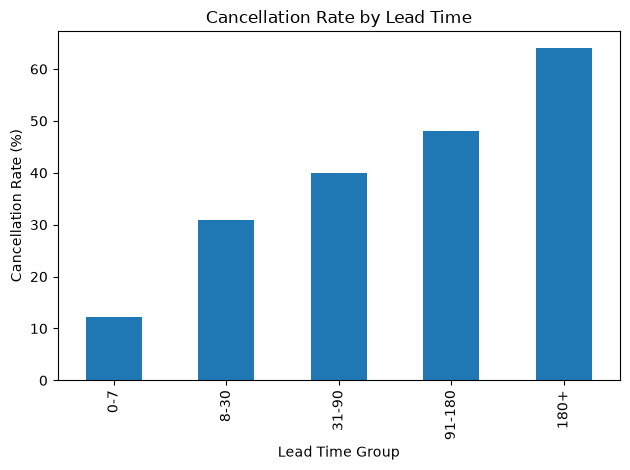

In [11]:
cancellation_by_leadtime["cancellation_rate"].plot(
    kind="bar",
    title="Cancellation Rate by Lead Time",
    xlabel="Lead Time Group",
    ylabel="Cancellation Rate (%)"
)

plt.tight_layout()
plt.show()

In [12]:
lost_data.to_csv(OUTPUT_DIR / "lost_data.csv")